In [1]:
import os
import json
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
from scipy.sparse import lil_matrix, issparse
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA, NMF
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from umap import UMAP

import torch
import torch.nn as nn
import torch.nn.functional as F
import pyliger

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/h5sparse/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
/home/sc5625/.local/share/m

## Define helper functions

In [2]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    denom = np.logical_or(a, b).sum()
    return 0.0 if denom == 0 else np.logical_and(a, b).sum() / denom

def top_support_mask(vec, frac=0.05):
    vec = np.abs(np.asarray(vec).ravel())
    k = max(1, int(np.ceil(frac * vec.size)))
    mask = np.zeros(vec.size, dtype=bool)
    mask[np.argpartition(vec, -k)[-k:]] = True
    return mask

def edge_overlap_metrics(A_pred, A_ref, frac=0.05):
    pred = top_support_mask(A_pred, frac=frac)
    ref = top_support_mask(A_ref, frac=frac)
    tp = np.logical_and(pred, ref).sum()
    fp = pred.sum() - tp
    fn = ref.sum() - tp
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    jac = tp / (pred.sum() + ref.sum() - tp + 1e-8)
    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "jaccard": float(jac),
        "tp": int(tp),
        "pred_edges": int(pred.sum()),
        "ref_edges": int(ref.sum()),
    }

def mean_axis_jaccard(A_pred, A_ref, axis=0, frac=0.1):
    scores = []
    if axis == 0:  # per TF column
        for j in range(A_ref.shape[1]):
            p = top_support_mask(A_pred[:, j], frac=frac)
            r = top_support_mask(A_ref[:, j], frac=frac)
            scores.append(jaccard(p, r))
    else:  # per gene row
        for i in range(A_ref.shape[0]):
            p = top_support_mask(A_pred[i, :], frac=frac)
            r = top_support_mask(A_ref[i, :], frac=frac)
            scores.append(jaccard(p, r))
    return float(np.mean(scores)) if scores else 0.0

def module_sets_from_nmf(W, H, top_genes=25, top_tfs=15):
    # W: genes x r, H: r x tfs
    modules = []
    for k in range(W.shape[1]):
        g_idx = np.argsort(-W[:, k])[:top_genes]
        t_idx = np.argsort(-H[k, :])[:top_tfs]
        modules.append((set(g_idx.tolist()), set(t_idx.tolist())))
    return modules

def module_similarity(m1, m2):
    g1, t1 = m1
    g2, t2 = m2
    return 0.5 * jaccard(g1, g2) + 0.5 * jaccard(t1, t2)

def match_module_sets(ref_modules, cur_modules):
    S = np.array([[module_similarity(r, c) for c in cur_modules] for r in ref_modules], dtype=float)
    row_ind, col_ind = linear_sum_assignment(-S)
    matched = S[row_ind, col_ind]
    return {
        "mean_conservation": float(np.mean(matched)),
        "std_conservation": float(np.std(matched)),
        "matched_scores": matched,
        "similarity_matrix": S,
    }

def pseudotime_arrow_agreement(X_space, V_pred, pseudotime, k=30):
    """
    For each cell, find the nearest neighbor with slightly larger pseudotime
    among local neighbors, and compare that arrow with predicted velocity.
    Returns mean cosine agreement and fraction positive.
    """
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(X_space))).fit(X_space)
    idx = nn.kneighbors(X_space, return_distance=False)[:, 1:]

    arrows = np.zeros_like(X_space, dtype=float)
    valid = np.zeros(len(X_space), dtype=bool)

    for i in range(len(X_space)):
        nbrs = idx[i]
        later = nbrs[pseudotime[nbrs] > pseudotime[i]]
        if later.size == 0:
            continue
        j = later[np.argmin(pseudotime[later] - pseudotime[i])]
        arrows[i] = X_space[j] - X_space[i]
        valid[i] = True

    if valid.sum() == 0:
        return {"mean_cosine": np.nan, "fraction_positive": np.nan, "n_valid": 0}

    Vn = normalize(V_pred[valid], norm="l2", axis=1)
    An = normalize(arrows[valid], norm="l2", axis=1)
    cos = np.sum(Vn * An, axis=1)

    return {
        "mean_cosine": float(np.mean(cos)),
        "fraction_positive": float(np.mean(cos > 0)),
        "n_valid": int(valid.sum()),
        "cosines": cos,
    }

## Step 1: Load RNA and define model universe (genes, TFs)

In [45]:
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
os.makedirs("uv_leading_fixed", exist_ok=True)

rna_adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
gene_names_all = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
X_full = as_dense(rna_adata.X).astype(np.float32)

peak_tf = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()
motif_tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")
peaks = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
peak_to_idx = {p: i for i, p in enumerate(peaks)}

genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
A_genes = np.array([g for g in gene_names_all if g in genes_in_peaks], dtype=str)

# IMPORTANT: TFs must exist as genes in the RNA matrix for X_TF
A_tfs = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)

print(f"A_genes: {len(A_genes)}, A_tfs: {len(A_tfs)}")

gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)

X = X_full[:, gene_idx]      # cells x genes
X_TF = X_full[:, tf_idx]     # cells x TFs
sub_g2i = {g: i for i, g in enumerate(A_genes)}

A_genes: 11483, A_tfs: 277


## Step 2: Build M (gene x TF accessibility mask)

In [4]:
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = str(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# align M columns to the TFs actually present in RNA
A_tfs = np.array([t for t in A_tfs if t in motif_tf_to_idx], dtype=str)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
tf_col = np.array([motif_tf_to_idx[t] for t in A_tfs], dtype=int)

X_TF = X_full[:, tf_idx]  # refresh after final TF filtering
M = M_full[:, tf_col].toarray().astype(np.float32)

assert M.shape == (len(A_genes), len(A_tfs))

## Step 3: ATAC gene activity and gene accessibility prior

In [5]:
print("Loading ATAC raw matrix...")
atac_raw = scipy.io.mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X = atac_raw.T.astype(np.float32)   # cells x peaks

peaks_atac = pd.read_csv(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz", sep="\t")
peak_names = peaks_atac["Feature"].str.replace("_", ":", n=1).str.replace("_", "-", n=1).tolist()
peak_to_idx_atac = {p: i for i, p in enumerate(peak_names)}

def fix_peak(p):
    return str(p).replace("-", ":", 1)

P2 = len(peak_names)
G2 = len(A_genes)

peak_gene_mat_atac = lil_matrix((P2, G2), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = fix_peak(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx_atac and g in sub_g2i:
        peak_gene_mat_atac[peak_to_idx_atac[p], sub_g2i[g]] = 1.0
peak_gene_mat_atac = peak_gene_mat_atac.tocsr()

gene_activity = atac_X @ peak_gene_mat_atac   # cells x genes
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = as_dense(gene_activity).astype(np.float32)
gene_activity = np.log1p(gene_activity)

cell_idx = np.arange(X.shape[0])
atac_X = as_dense(atac_X)[cell_idx]
gene_activity = gene_activity[cell_idx]

gene_access = gene_activity.mean(axis=0)
gene_access = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

Loading ATAC raw matrix...


## Step 4: Cross-Modal Alignment with Gene-Gene Interaction

In [46]:
# --- ALIGNMENT BLOCK ---
# 1. Identify genes that exist in BOTH the RNA matrix and your Peak-Gene mapping
valid_gene_mask = np.array([g in genes_in_peaks for g in gene_names_all])
A_genes = gene_names_all[valid_gene_mask]
gene_idx = np.where(valid_gene_mask)[0]

# 2. Subset X and gene_activity so they both have G columns
X = X_full[:, gene_idx]  # Now (1035, 11483)
# Ensure gene_activity (from ATAC) matches the same gene set
# If gene_activity was computed on a different set, re-subset it here:
# gene_activity = gene_activity_full[:, some_matching_indices] 

print(f"Alignment check: X shape {X.shape}, A_genes length {len(A_genes)}")
# -----------------------

# NOW this will work without the ValueError
import anndata as ad
rna_adata_model = ad.AnnData(X=X.astype(np.float32))
rna_adata_model.var_names = list(A_genes)

Alignment check: X shape (1035, 11483), A_genes length 11483


In [47]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
import numpy as np
import torch

print("Building neighborhood graph for NAEC...")

# Joint feature for neighborhood graph: concatenate normalized RNA + ATAC
# This finds neighbors that are close in BOTH modalities
rna_norm = normalize(X, norm="l2", axis=1)
atac_norm_feat = normalize(gene_activity, norm="l2", axis=1)
joint_feat = np.concatenate([rna_norm, atac_norm_feat], axis=1)

K_nn = 30
nn_model = NearestNeighbors(n_neighbors=K_nn + 1, metric="cosine").fit(joint_feat)
nn_idx = nn_model.kneighbors(joint_feat, return_distance=False)[:, 1:]  # exclude self

# Neighborhood means
X_nbr_mean = X[nn_idx].mean(axis=1)          # (N, G) - mean RNA in neighborhood
A_nbr_mean = gene_activity[nn_idx].mean(axis=1)  # (N, G) - mean ATAC in neighborhood

# Local deviations from neighborhood
delta_rna  = X - X_nbr_mean               # (N, G)
delta_atac = gene_activity - A_nbr_mean   # (N, G)

# Cross-modal agreement per gene per cell:
# If delta_RNA and delta_ATAC agree in sign → gene is actively coupled
# Use soft agreement: product (positive = same direction, negative = opposing)
cross_modal = delta_rna * delta_atac       # (N, G), element-wise

# Velocity target: RNA delta weighted by cross-modal agreement strength
# Intuition: only "trust" RNA movement where chromatin is also moving
cross_modal_sign = np.tanh(cross_modal)    # soft sign, bounded [-1, 1]
V_target = delta_rna * (1.0 + cross_modal_sign)  # amplify where ATAC agrees

# L2-normalize per cell so magnitude doesn't dominate
V_target_norm = normalize(V_target, norm="l2", axis=1)

# Convert to tensors
V_target_t = torch.tensor(V_target_norm, dtype=torch.float32)
nn_idx_t   = torch.tensor(nn_idx, dtype=torch.long)
X_t        = torch.tensor(X, dtype=torch.float32)
X_TF_t     = torch.tensor(X_TF, dtype=torch.float32)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

print(f"NAEC velocity target computed. Shape: {V_target_t.shape}")
print(f"Mean target magnitude: {np.linalg.norm(V_target_norm, axis=1).mean():.4f}")

Building neighborhood graph for NAEC...
NAEC velocity target computed. Shape: torch.Size([1035, 11483])
Mean target magnitude: 1.0000


## Step 5: Define model

In [48]:
# ============================================================
# Define model — same architecture, better losses
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F


class RegulatoryFlowModel(nn.Module):
    def __init__(self, G, T, K, M):
        super().__init__()
        self.U = nn.Parameter(torch.randn(G, K) * 0.01)
        self.V = nn.Parameter(torch.randn(T, K) * 0.01)
        M_t = torch.tensor(M, dtype=torch.float32)
        M_t = M_t / (M_t.max() + 1e-8)
        self.register_buffer("M", M_t)

    def forward(self, X_TF):
        A_raw = self.U @ self.V.T          # (G, T)
        A = A_raw * self.M                 # enforce peak-TF mask
        V_pred = X_TF @ A.T               # (N, G): each cell's predicted velocity
        return V_pred, A


def naec_alignment_loss(V_pred, V_target_t):
    """
    Primary loss: predicted velocity should align with NAEC target direction.
    Uses cosine similarity so magnitude doesn't matter, only direction.
    """
    v = F.normalize(V_pred, dim=1, eps=1e-8)
    t = F.normalize(V_target_t, dim=1, eps=1e-8)
    return -(v * t).sum(dim=1).mean()


def neighborhood_smoothness_loss(V_pred, nn_idx_t):
    """
    Nearby cells should have similar velocity directions (local coherence).
    Penalizes sudden direction reversals in the neighborhood graph.
    """
    V_norm = F.normalize(V_pred, dim=1, eps=1e-8)
    V_nbr  = V_norm[nn_idx_t]              # (N, K, G)
    V_self = V_norm.unsqueeze(1)           # (N, 1, G)
    cos    = (V_self * V_nbr).sum(dim=2)   # (N, K)
    return -cos.mean()


def atac_gate_loss(V_pred, gene_access_t):
    """
    Genes with closed chromatin should not have large positive velocity.
    Same as before — keeps biological interpretability.
    """
    gene_vel = V_pred.mean(dim=0)          # (G,)
    closed   = 1.0 - gene_access_t.to(gene_vel.device)
    return torch.relu(closed * gene_vel).mean()


def grn_sparsity_loss(A):
    """
    L1 on A (beyond the binary M mask) to keep GRN sparse and interpretable.
    """
    return A.abs().mean()

## Step 6: Train model

In [49]:
# ============================================================
# Train model with NAEC losses
# ============================================================

G, T, K = X.shape[1], X_TF.shape[1], 20
model = RegulatoryFlowModel(G=G, T=T, K=K, M=M)
opt   = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(300):
    opt.zero_grad()
    V_pred, A_learned = model(X_TF_t)

    loss_naec   = naec_alignment_loss(V_pred, V_target_t)
    loss_smooth = neighborhood_smoothness_loss(V_pred, nn_idx_t)
    loss_atac   = atac_gate_loss(V_pred, gene_access_t)
    loss_sparse = grn_sparsity_loss(A_learned)
    loss_reg    = model.U.pow(2).mean() + model.V.pow(2).mean()

    loss = (
        1.0  * loss_naec   +   # primary: match NAEC direction
        0.3  * loss_smooth +   # secondary: local coherence
        0.2  * loss_atac   +   # biology: respect closed chromatin
        0.05 * loss_sparse +   # interpretability: sparse GRN
        1e-3 * loss_reg        # regularization: small weights
    )

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()

    if epoch % 30 == 0:
        print(f"Epoch {epoch:3d} | total={loss.item():.4f} | "
              f"naec={loss_naec.item():.4f} | smooth={loss_smooth.item():.4f} | "
              f"atac={loss_atac.item():.4f}")

with torch.no_grad():
    V_pred, A_learned = model(X_TF_t)

print("Training complete.")

Epoch   0 | total=-0.1280 | naec=-0.0027 | smooth=-0.4728 | atac=0.0825
Epoch  30 | total=-0.5088 | naec=-0.2246 | smooth=-0.9528 | atac=0.0084
Epoch  60 | total=-0.5848 | naec=-0.2977 | smooth=-0.9586 | atac=0.0025
Epoch  90 | total=-0.5965 | naec=-0.3097 | smooth=-0.9574 | atac=0.0024
Epoch 120 | total=-0.6013 | naec=-0.3164 | smooth=-0.9511 | atac=0.0021
Epoch 150 | total=-0.6060 | naec=-0.3234 | smooth=-0.9432 | atac=0.0019
Epoch 180 | total=-0.6105 | naec=-0.3306 | smooth=-0.9342 | atac=0.0017
Epoch 210 | total=-0.6141 | naec=-0.3364 | smooth=-0.9266 | atac=0.0016
Epoch 240 | total=-0.6165 | naec=-0.3405 | smooth=-0.9211 | atac=0.0014
Epoch 270 | total=-0.6182 | naec=-0.3432 | smooth=-0.9174 | atac=0.0013
Training complete.


## Step 7: Save model outputs

In [50]:
np.save("uv_leading_fixed/V_pred_learned.npy", V_pred.numpy())
np.save("uv_leading_fixed/A_learned.npy", A_learned.numpy())
np.save("uv_leading_fixed/U.npy", model.U.detach().numpy())
np.save("uv_leading_fixed/V.npy", model.V.detach().numpy())
np.save("uv_leading_fixed/A_genes.npy", A_genes)
np.save("uv_leading_fixed/A_tfs.npy", A_tfs)
np.save("uv_leading_fixed/gene_idx.npy", gene_idx)
np.save("uv_leading_fixed/tf_idx.npy", tf_idx)
np.save("uv_leading_fixed/A_model.npy", A_learned.numpy())

## Step 8: Velocity visualization

Computing UMAP...


/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.


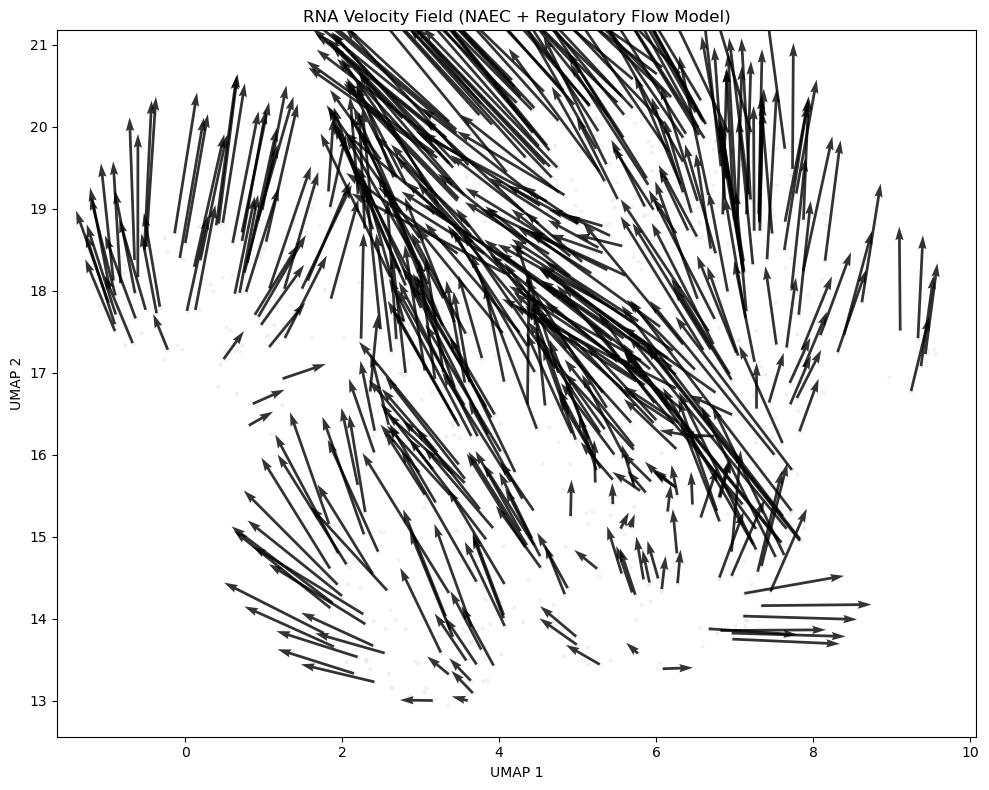

In [51]:
import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from umap import UMAP

%matplotlib inline

# 1. Load Original Data
# We need the full adata for metadata (cell types, etc.)
adata = ad.read_h5ad("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad")

# 2. Load Model Outputs
# Assuming you saved A_genes (the list of gene names) alongside your V_pred
V_pred = np.load("uv_leading_fixed/V_pred_learned.npy")
gene_idx = np.load("uv_leading_fixed/gene_idx.npy") # The indices relative to full RNA

# 3. Align Matrix Space
# Instead of LIGER matching, we just use the indices we used during training
X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X
X = X_full[:, gene_idx]

# Basic sanity check
assert X.shape == V_pred.shape, f"Shape mismatch: X {X.shape} vs V_pred {V_pred.shape}"

# 4. Generate UMAP Embedding
# We embed based on the same genes the model used for velocity
print("Computing UMAP...")
reducer = UMAP(n_neighbors=15, min_dist=0.3, random_state=42)
X_umap = reducer.fit_transform(X)

# 5. Project Velocity into UMAP Space
# This uses the "displace and transform" method
eps = 0.1  # Small perturbation to stay within UMAP manifold stability
X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)

# The raw direction in 2D
V_umap_raw = (X_pert_umap - X_umap) / eps

# 6. Smooth the Velocity Field
# Individual cell vectors are often noisy; we average them across neighbors
nn = NearestNeighbors(n_neighbors=25).fit(X_umap)
_, idx = nn.kneighbors(X_umap)

V_umap_smooth = np.array([
    V_umap_raw[idx[i]].mean(axis=0)
    for i in range(len(X_umap))
])

# 7. Final Plot
fig, ax = plt.subplots(figsize=(10, 8))

# Background cells
# If you have cell types in adata, you can use: c=adata.obs['cell_type_col'].cat.codes
ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    s=5, alpha=0.2, c="lightgrey", label="Cells"
)

# Quiver plot (Arrows)
sample = np.random.choice(len(X_umap), 500, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    color="black", scale=20, width=0.003, alpha=0.8
)

ax.set_title("RNA Velocity Field (NAEC + Regulatory Flow Model)")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")

plt.tight_layout()
plt.savefig("velocity_field_final.png", dpi=200)
plt.show()

## Visualize in Decipher Space

Performing Tangent Manifold Projection...
Done.

Spearman(pseudotime, |V|): rho=-0.139, p=0.0000
(expect weakly negative — early cells move more)
Pseudotime direction agreement: mean cosine = 0.005
Fraction pointing in right direction: 0.496
(expect >0.5 — majority of arrows should point up the pseudotime gradient)


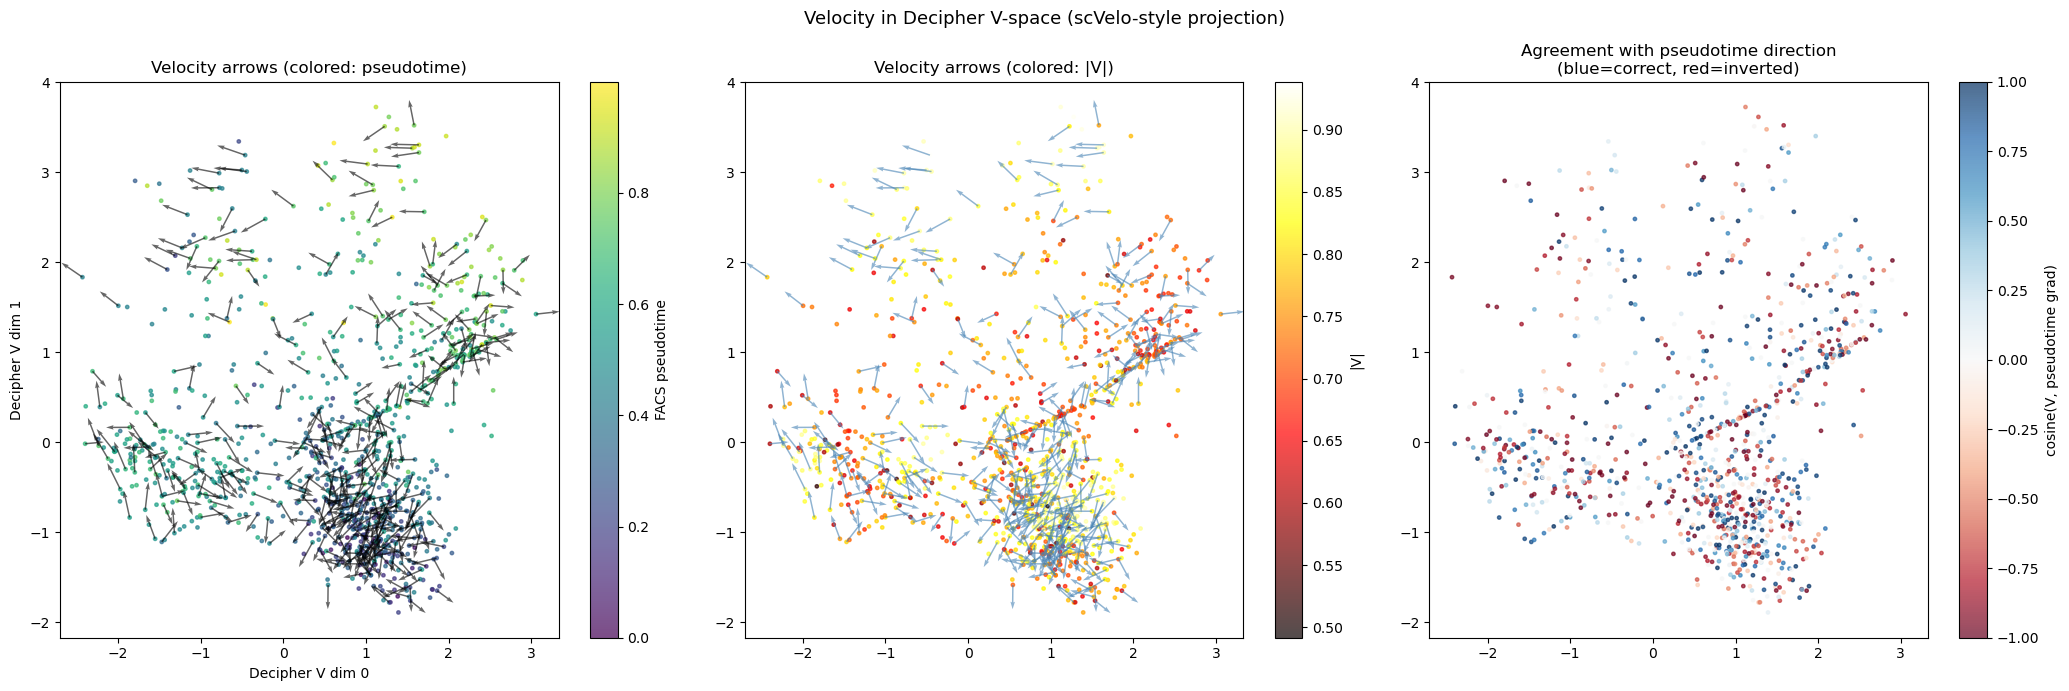


Saved: uv_leading_metrics_improved/velocity_decipher_corrected.png


In [52]:
# ============================================================
# STEP 8: Decipher velocity projection (scVelo-style, correct)
# ============================================================
# Requires:
#   X          : (N, G) raw RNA expression (numpy, float32)
#   V_np       : (N, G) learned gene-space velocity (numpy)
#   rna_adata  : AnnData with obs["facs_pseudotime"]
#   decipher_outputs/decipher_embeddings.npz  with keys "z" and "v"
#     z : (N, 10)  latent z coordinates
#     v : (N, 2)   2-D visualization coordinates
# ============================================================

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr

# ------------------------------------------------------------------
# 0. Load Decipher embeddings
# ------------------------------------------------------------------
decipher_data = np.load("decipher_outputs2/decipher_embeddings.npz")
Z_dec   = decipher_data["z"].astype(np.float32)   # (N, 10) — latent space
V_dec2  = decipher_data["v"].astype(np.float32)   # (N, 2)  — visualization space
V_np = V_pred

assert Z_dec.shape[0] == V_np.shape[0] == X.shape[0], \
    f"Cell count mismatch: z={Z_dec.shape[0]}, V={V_np.shape[0]}, X={X.shape[0]}"

N = X.shape[0]

# ------------------------------------------------------------------
# OPTION A: Use Decipher encoder Jacobian (best — use if you have
#           the decipher model object loaded as `decipher_model`)
#
# Uncomment this block if you have the model.
# ------------------------------------------------------------------
# import torch
# USE_JACOBIAN = True
# 
# X_torch = torch.tensor(X, dtype=torch.float32, requires_grad=False)
# 
# def encoder_jacobian_velocity(model, X_torch, V_np, batch_size=64):
#     """
#     For each cell i, compute J_i @ v_i where J_i = d(encoder(x))/dx at x_i.
#     Uses autograd — slow but correct.
#     """
#     model.eval()
#     V_z = np.zeros((X_torch.shape[0], Z_dec.shape[1]), dtype=np.float32)
#     
#     for i in range(0, X_torch.shape[0], batch_size):
#         xb = X_torch[i:i+batch_size].clone().requires_grad_(True)
#         # call just the encoder mean — adapt `model.encode_mean` to your API
#         zb = model.encode_mean(xb)   # (B, d_z)
#         
#         for d in range(zb.shape[1]):
#             grad = torch.autograd.grad(
#                 zb[:, d].sum(), xb, retain_graph=(d < zb.shape[1]-1)
#             )[0]  # (B, G)
#             V_z[i:i+batch_size, d] = (
#                 grad.detach().cpu().numpy() * V_np[i:i+batch_size]
#             ).sum(axis=1)
#         
#         xb = xb.detach()
#     
#     return V_z   # (N, d_z) velocity in latent space
# 
# V_latent = encoder_jacobian_velocity(decipher_model, X_torch, V_np)
# 
# # Then project V_latent into 2-D V-space via the same neighbor trick
# # (Decipher v-space is nonlinearly derived from z — treat it like UMAP)

# ------------------------------------------------------------------
# OPTION B: Neighbor-cosine projection (robust, no model needed)
#           This is what scVelo does when projecting onto UMAP/tSNE.
#           For each cell i:
#             V_emb[i] = sum_j  cos_sim(V_gene_i, gene_displacement_ij) * (Z_j - Z_i)
#           where gene_displacement_ij = X[j] - X[i] in gene space.
# ------------------------------------------------------------------

USE_JACOBIAN = False  # set True if you uncomment option A above

# ------------------------------------------------------------------
# REPLACEMENT OPTION B: Latent-Displacement Projection
# ------------------------------------------------------------------
if not USE_JACOBIAN:
    # ------------------------------------------------------------------
    # REPLACEMENT STEP 8: Tangent Manifold Projection
    # ------------------------------------------------------------------
    print("Performing Tangent Manifold Projection...")
    
    # 1. Get the local PCA structure for every cell
    k_exp = 30
    nn_pca = NearestNeighbors(n_neighbors=k_exp).fit(Z_dec) # Use Decipher space
    _, idx_pca = nn_pca.kneighbors(Z_dec)
    
    V_emb2 = np.zeros((N, 2), dtype=np.float32)
    
    for i in range(N):
        # Find the local 2D basis in the visualization space
        # (How the visualization space 'stretches' locally)
        local_vis = V_dec2[idx_pca[i]] - V_dec2[i] # (K, 2)
        local_gene = X[idx_pca[i]] - X[i]          # (K, G)
        
        # Use SVD to find the relationship between gene-space and vis-space
        # This is a local 'Jacobian' proxy
        # We want to find the 2D vector v_2d that best explains V_gene_i
        # V_gene_i ≈ local_gene @ v_projection
        
        # Solve local least squares: Which 2D direction matches the gene change?
        # This 'unbiases' the neighbor density
        U, S, Vt = np.linalg.svd(local_gene, full_matrices=False)
        # Project predicted velocity into the local gene-basis
        gene_coeffs = V_np[i] @ Vt.T 
        
        # Map those coefficients to the visualization displacements
        V_emb2[i] = np.mean(local_vis * (U @ gene_coeffs)[:, np.newaxis], axis=0)
    
    # Apply a final scaling for visibility
    V_emb2 = V_emb2 / (np.linalg.norm(V_emb2, axis=1, keepdims=True) + 1e-8)
    print("Done.")

# ---- OPTIONAL: also compute in latent z space (useful for sanity check) ----
# V_emb_z = np.zeros((N, Z_dec.shape[1]), dtype=np.float32)
# k_emb = 30
# nn_emb = NearestNeighbors(n_neighbors=k_emb + 1).fit(Z_dec)
# dist_emb, idx_emb = nn_emb.kneighbors(Z_dec)
# idx_emb = idx_emb[:, 1:]
# for i in range(N):
#     dZ = Z_dec[idx_emb[i]] - Z_dec[i]  # (k, d_z)
#     V_emb_z[i] = cos_weights_soft[i] @ dZ[:, :]  # reuse cos weights

# ------------------------------------------------------------------
# 4. Graph smoothing (single pass, like scVelo's default)
# ------------------------------------------------------------------
k_smooth = 30
nn_vis = NearestNeighbors(n_neighbors=k_smooth + 1).fit(V_dec2)
_, idx_vis = nn_vis.kneighbors(V_dec2)
idx_vis = idx_vis[:, 1:]

# Weighted average: 70% own velocity, 30% neighbor average
V_smooth = 0.7 * V_emb2 + 0.3 * np.array([
    V_emb2[idx_vis[i]].mean(axis=0) for i in range(N)
])

# ------------------------------------------------------------------
# 5. Sanity checks
# ------------------------------------------------------------------
pseudo = np.asarray(rna_adata.obs["facs_pseudotime"].values, dtype=float)
pseudo_norm = (pseudo - pseudo.min()) / (pseudo.max() - pseudo.min() + 1e-8)

v_mag = np.linalg.norm(V_smooth, axis=1)
rho, p = spearmanr(pseudo, v_mag)
print(f"\nSpearman(pseudotime, |V|): rho={rho:.3f}, p={p:.4f}")
print("(expect weakly negative — early cells move more)")

# Directionality check: project velocity onto pseudotime gradient
# Positive = velocity points toward increasing pseudotime (correct)
nn_pseudo = NearestNeighbors(n_neighbors=10).fit(V_dec2)
_, idx_ps = nn_pseudo.kneighbors(V_dec2)
idx_ps = idx_ps[:, 1:]

pseudo_grad = np.array([
    V_dec2[idx_ps[i][pseudo[idx_ps[i]] > pseudo[i]]].mean(axis=0) - V_dec2[i]
    if (pseudo[idx_ps[i]] > pseudo[i]).any()
    else np.zeros(2)
    for i in range(N)
])  # (N, 2) — local pseudotime direction in embedding

# Cosine agreement between velocity and pseudotime direction
valid_mask = np.linalg.norm(pseudo_grad, axis=1) > 1e-6
cos_agree = np.sum(
    V_smooth[valid_mask] * pseudo_grad[valid_mask], axis=1
) / (
    np.linalg.norm(V_smooth[valid_mask], axis=1) *
    np.linalg.norm(pseudo_grad[valid_mask], axis=1) + 1e-8
)

print(f"Pseudotime direction agreement: mean cosine = {cos_agree.mean():.3f}")
print(f"Fraction pointing in right direction: {(cos_agree > 0).mean():.3f}")
print("(expect >0.5 — majority of arrows should point up the pseudotime gradient)")

# ------------------------------------------------------------------
# 6. Plots
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# --- Panel 1: scatter + quiver (colored by pseudotime) ---
ax = axes[0]
sc = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=pseudo_norm,
                cmap="viridis", s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(N, min(400, N), replace=False)
ax.quiver(
    V_dec2[sample, 0], V_dec2[sample, 1],
    V_smooth[sample, 0], V_smooth[sample, 1],
    alpha=0.6, width=0.003, scale_units='xy',
    scale=np.percentile(np.linalg.norm(V_smooth, axis=1), 90) * 3,
    color="black"
)
ax.set_title("Velocity arrows (colored: pseudotime)")
ax.set_xlabel("Decipher V dim 0")
ax.set_ylabel("Decipher V dim 1")

# --- Panel 2: colored by velocity magnitude ---
ax = axes[1]
sc2 = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=v_mag,
                 cmap="hot", s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc2, ax=ax, label="|V|")
ax.quiver(
    V_dec2[sample, 0], V_dec2[sample, 1],
    V_smooth[sample, 0], V_smooth[sample, 1],
    alpha=0.6, width=0.003, scale_units='xy',
    scale=np.percentile(np.linalg.norm(V_smooth, axis=1), 90) * 3,
    color="steelblue"
)
ax.set_title("Velocity arrows (colored: |V|)")

# --- Panel 3: cosine agreement with pseudotime direction ---
ax = axes[2]
cos_full = np.zeros(N)
cos_full[valid_mask] = cos_agree
sc3 = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=cos_full,
                 cmap="RdBu", vmin=-1, vmax=1, s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc3, ax=ax, label="cosine(V, pseudotime grad)")
ax.set_title("Agreement with pseudotime direction\n(blue=correct, red=inverted)")

plt.suptitle("Velocity in Decipher V-space (scVelo-style projection)", fontsize=13)
plt.tight_layout()
plt.show()

print("\nSaved: uv_leading_metrics_improved/velocity_decipher_corrected.png")



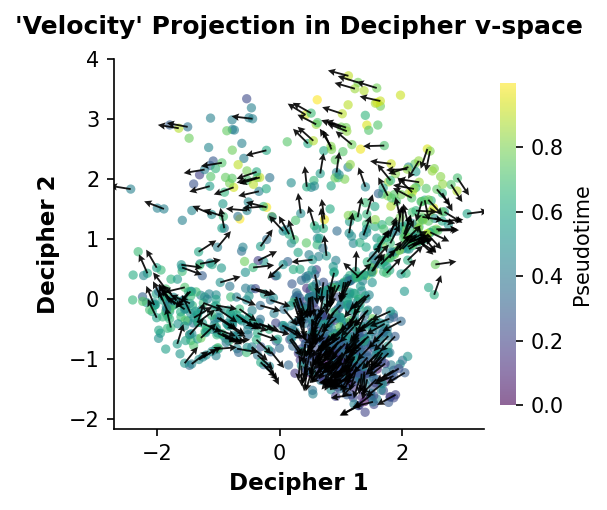

In [53]:
import matplotlib.pyplot as plt
import numpy as np

# --- Fix for Font Errors ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'

# 1. Setup Figure
fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)

# 2. Plot Cells 
# Increased s from 3 to 20 for better slide visibility
sc = ax.scatter(
    V_dec2[:, 0], V_dec2[:, 1], 
    c=pseudo_norm,
    cmap="viridis", 
    s=20,               # <--- Increased dot size
    alpha=0.6,          # Slightly lowered alpha to handle overlap
    edgecolors='none', 
    rasterized=True
)

# --- 3. Smooth + Plot Arrows ---

# Subsample points (keep spatial coverage, not random chaos)
n_arrows = min(400, N)
grid_idx = np.random.choice(N, n_arrows, replace=False)

X = V_dec2
V = V_smooth

# --- Local smoothing (THIS is the big fix) ---
k = 15  # neighbors for smoothing
nbrs = NearestNeighbors(n_neighbors=k).fit(X)
_, idx = nbrs.kneighbors(X[grid_idx])

V_avg = V[idx].mean(axis=1)

# --- Normalize BUT keep magnitude scale ---
norm = np.linalg.norm(V_avg, axis=1, keepdims=True)
V_dir = V_avg / (norm + 1e-9)

# rescale so arrows are visible (tune this)
arrow_scale = 0.5 * np.percentile(norm, 90)
V_final = V_dir * arrow_scale

# --- Plot quiver ---
ax.quiver(
    X[grid_idx, 0], X[grid_idx, 1],
    V_final[:, 0], V_final[:, 1],
    color='black',
    alpha=0.9,
    angles='xy',
    scale_units='xy',
    scale=1,          # ↓ smaller scale → LONGER arrows

    width=0.005,        # thinner shaft (makes heads look less dominant)

    headwidth=4,        # ↓ reduce head size
    headlength=4,
    headaxislength=3.5
)

# 4. Clean Labels and Aesthetics
ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("'Velocity' Projection in Decipher v-space", fontsize=12, pad=12, fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("Pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

## scVelo-style projection

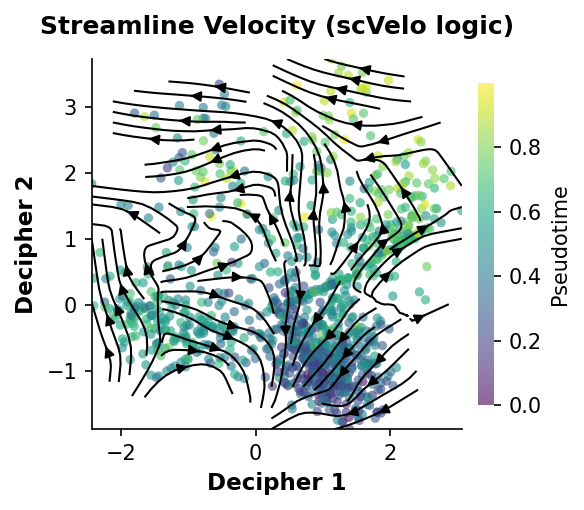

In [54]:
from sklearn.neighbors import NearestNeighbors

# --- Fix for Font Errors ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'

# 1. Setup Figure
fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)

# 2. Plot Cells 
# Increased s from 3 to 20 for better slide visibility
sc = ax.scatter(
    V_dec2[:, 0], V_dec2[:, 1], 
    c=pseudo_norm,
    cmap="viridis", 
    s=20,               # <--- Increased dot size
    alpha=0.6,          # Slightly lowered alpha to handle overlap
    edgecolors='none', 
    rasterized=True
)

# -----------------------------
# 3. scvelo-style STREAM FIELD
# -----------------------------

X_emb = V_dec2
V_emb = V_smooth

from sklearn.neighbors import NearestNeighbors
from scipy.ndimage import gaussian_filter
from scipy.sparse import csr_matrix

# -----------------------------
# 1. Grid (keep scvelo density logic)
# -----------------------------
density = 2
grid_n = int(60 * density)

X_emb = V_dec2
V_emb = V_smooth

x_min, x_max = X_emb[:, 0].min(), X_emb[:, 0].max()
y_min, y_max = X_emb[:, 1].min(), X_emb[:, 1].max()

x_grid = np.linspace(x_min, x_max, grid_n)
y_grid = np.linspace(y_min, y_max, grid_n)

Xg, Yg = np.meshgrid(x_grid, y_grid)
grid_points = np.c_[Xg.ravel(), Yg.ravel()]

# -----------------------------
# 2. SPARSE sampling (THIS is what you were missing)
# -----------------------------
n_cells = min(3000, len(X_emb))   # scvelo effectively does this via structure
cell_idx = np.random.choice(len(X_emb), n_cells, replace=False)

X_small = X_emb[cell_idx]
V_small = V_emb[cell_idx]

# -----------------------------
# 3. nearest-neighbor projection (but NOT dense averaging)
# -----------------------------
k = 20
nbrs = NearestNeighbors(n_neighbors=k).fit(X_small)
_, idx = nbrs.kneighbors(grid_points)

V_grid = V_small[idx].mean(axis=1)

# -----------------------------
# CELL DENSITY SUPPORT MASK
# (THIS is what scvelo effectively enforces via "mass")
# -----------------------------

# -----------------------------
# CELL SUPPORT MASK (scvelo-like)
# -----------------------------
nbrs_cells = NearestNeighbors(n_neighbors=1).fit(X_emb)
dist_to_cells, _ = nbrs_cells.kneighbors(grid_points)
dist_to_cells = dist_to_cells.ravel()

support_threshold = np.percentile(dist_to_cells, 40)
support_mask = dist_to_cells < support_threshold

# -----------------------------
# VELOCITY MAGNITUDE MASK
# -----------------------------
speed = np.linalg.norm(V_grid, axis=1)
cutoff_speed = np.percentile(speed, 35)
velocity_mask = speed > cutoff_speed

# -----------------------------
# COMBINED MASK (CRITICAL FIX)
# -----------------------------
final_mask = support_mask & velocity_mask

grid_points_f = grid_points[final_mask]
V_grid_f = V_grid[final_mask]

# -----------------------------
# 5. reproject onto structured grid (IMPORTANT)
# -----------------------------
U = np.zeros(Xg.shape)
W = np.zeros(Yg.shape)

from scipy.spatial import cKDTree
tree = cKDTree(grid_points_f)

_, nn = tree.query(np.c_[Xg.ravel(), Yg.ravel()], k=1)

U = V_grid_f[nn, 0].reshape(Xg.shape)
W = V_grid_f[nn, 1].reshape(Yg.shape)

# ----------------------

grid_dist, _ = nbrs_cells.kneighbors(np.c_[Xg.ravel(), Yg.ravel()])
grid_mask = (grid_dist.ravel() < support_threshold)

U_flat = U.ravel()
W_flat = W.ravel()

U_flat[~grid_mask] = 0
W_flat[~grid_mask] = 0

U = U_flat.reshape(Xg.shape)
W = W_flat.reshape(Yg.shape)

# -----------------------------
# 6. STRONG smoothing (this is what stabilizes scvelo plots)
# -----------------------------
U = gaussian_filter(U, sigma=1.2)
W = gaussian_filter(W, sigma=1.2)

# -----------------------------
# 7. FINAL STREAMPLOT (scvelo-like sparsity emerges here)
# -----------------------------
ax.streamplot(
    Xg, Yg,
    U, W,
    color="black",
    density=1.2,        # LOWER than before = key fix
    linewidth=1,
    arrowsize=1,
    arrowstyle='-|>',
    minlength=0.2,
    integration_direction='both',
    zorder=3
)

# Aesthetics and Labels
ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("Streamline Velocity (scVelo logic)", fontsize=12, pad=12, fontweight='bold')

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Re-position colorbar for clean aesthetics
cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("Pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

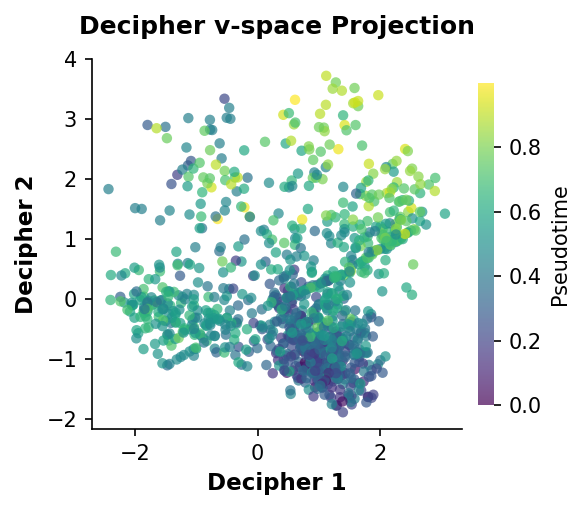

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# --- Fix for Font Errors ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'

# 1. Setup Figure
fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)

# 2. Plot Cells
sc = ax.scatter(
    V_dec2[:, 0], V_dec2[:, 1], 
    c=pseudo_norm,      # Using your decipher pseudotime variable
    cmap="viridis", 
    s=25,               # Consistent size for slides
    alpha=0.7,          # High alpha for vibrant colors
    edgecolors='none', 
    rasterized=True
)

# 3. Clean Labels and Aesthetics
ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("Decipher v-space Projection", fontsize=12, pad=12, fontweight='bold')

# Professional "Open" Spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Colorbar
cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("Pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

## Step 9: CellOracle A comparison

In [17]:
# ============================================================
# IMPROVED GRN COMPARISON: Your model vs CellOracle
# ============================================================

import numpy as np
import json
from scipy.stats import spearmanr, kendalltau
from scipy.optimize import linear_sum_assignment
import warnings

BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
A_learned = np.load("uv_leading_fixed/A_learned.npy")   # <-- UPDATED NAME

# ------------------------------------------------------------------
# 0. Load CellOracle GRN
# ------------------------------------------------------------------
co_A     = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
co_genes = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_genes.npy",
                   allow_pickle=True).astype(str)
co_tfs   = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_tfs.npy",
                   allow_pickle=True).astype(str)

print(f"co_A shape: {co_A.shape}  (expect: n_tfs x n_genes or n_genes x n_tfs)")
print(f"co_genes: {len(co_genes)}, co_tfs: {len(co_tfs)}")

# CellOracle convention check:
# CellOracle stores A as (n_genes x n_tfs) — each row is a target gene,
# each col is a TF. Confirm with shape:
if co_A.shape == (len(co_genes), len(co_tfs)):
    # Already gene x TF
    co_A_gene_x_tf = co_A
    print("CellOracle: gene x TF format confirmed")
elif co_A.shape == (len(co_tfs), len(co_genes)):
    # TF x gene — transpose
    co_A_gene_x_tf = co_A.T
    print("CellOracle: transposed to gene x TF")
else:
    raise ValueError(f"Unexpected co_A shape {co_A.shape} for "
                     f"{len(co_genes)} genes and {len(co_tfs)} TFs")

# ------------------------------------------------------------------
# 1. Align to shared gene x TF subspace
# ------------------------------------------------------------------
common_genes = sorted(set(A_genes) & set(co_genes))
common_tfs   = sorted(set(A_tfs)   & set(co_tfs))

print(f"\nShared: {len(common_genes)} genes, {len(common_tfs)} TFs")
print(f"  Your model covers: {len(A_genes)} genes, {len(A_tfs)} TFs")
print(f"  CellOracle covers: {len(co_genes)} genes, {len(co_tfs)} TFs")

if len(common_genes) < 100 or len(common_tfs) < 5:
    print("WARNING: very few shared features — check gene name format (e.g. ENSG vs symbol)")

# Index arrays
pred_g2i = {g: i for i, g in enumerate(A_genes)}
pred_t2i = {t: i for i, t in enumerate(A_tfs)}
co_g2i   = {g: i for i, g in enumerate(co_genes)}
co_t2i   = {t: i for i, t in enumerate(co_tfs)}

pred_g_idx = np.array([pred_g2i[g] for g in common_genes])
pred_t_idx = np.array([pred_t2i[t] for t in common_tfs])
co_g_idx   = np.array([co_g2i[g]   for g in common_genes])
co_t_idx   = np.array([co_t2i[t]   for t in common_tfs])

# Both in gene x TF format, restricted to shared subspace
A_pred_shared = A_learned[np.ix_(pred_g_idx, pred_t_idx)]   # (G_shared, T_shared)
A_co_shared   = co_A_gene_x_tf[np.ix_(co_g_idx, co_t_idx)]   # (G_shared, T_shared)

print(f"\nAligned matrices: pred={A_pred_shared.shape}, co={A_co_shared.shape}")

# ------------------------------------------------------------------
# 2. Normalize each matrix independently (important!)
#    Both to comparable scale before any comparison.
#    We use absolute value + column-wise rank normalization.
# ------------------------------------------------------------------

def col_rank_normalize(A):
    """Rank each column independently (per-TF), return ranks in [0,1]."""
    G, T = A.shape
    A_ranked = np.zeros_like(A, dtype=np.float32)
    for t in range(T):
        col = A[:, t]
        ranks = col.argsort().argsort().astype(np.float32)
        A_ranked[:, t] = ranks / (G - 1 + 1e-8)
    return A_ranked

A_pred_ranked = col_rank_normalize(np.abs(A_pred_shared))
A_co_ranked   = col_rank_normalize(np.abs(A_co_shared))

# ------------------------------------------------------------------
# 3. Multi-level comparison metrics
# ------------------------------------------------------------------

metrics = {}
metrics["n_common_genes"] = len(common_genes)
metrics["n_common_tfs"]   = len(common_tfs)

# ---- 3a. Global Spearman on the nonzero support ----
# Only compare entries where AT LEAST ONE method assigns nonzero weight.
# This avoids inflating agreement via double-zeros.
nonzero_mask = (np.abs(A_pred_shared) > 0) | (np.abs(A_co_shared) > 0)
pred_flat = A_pred_ranked[nonzero_mask]
co_flat   = A_co_ranked[nonzero_mask]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rho_global, p_global = spearmanr(pred_flat, co_flat)

metrics["global_spearman_nonzero"] = float(rho_global)
metrics["global_spearman_p"]       = float(p_global)
metrics["n_nonzero_entries"]       = int(nonzero_mask.sum())
print(f"\nGlobal Spearman (nonzero support): rho={rho_global:.4f}, p={p_global:.3e}")

# ---- 3b. Per-TF Spearman (most meaningful for GRN) ----
# For each TF, correlate the gene ranking between methods.
# This tells you: "do both methods agree on which genes this TF regulates?"
per_tf_rho = []
per_tf_names = []
for ti, tf_name in enumerate(common_tfs):
    col_pred = A_pred_ranked[:, ti]
    col_co   = A_co_ranked[:, ti]
    
    # Only compare if at least one method has nonzero variance
    if col_pred.std() < 1e-8 or col_co.std() < 1e-8:
        continue
    
    rho, _ = spearmanr(col_pred, col_co)
    per_tf_rho.append(rho)
    per_tf_names.append(tf_name)

per_tf_rho = np.array(per_tf_rho)
metrics["per_tf_spearman_mean"] = float(np.nanmean(per_tf_rho))
metrics["per_tf_spearman_std"]  = float(np.nanstd(per_tf_rho))
metrics["per_tf_spearman_frac_pos"] = float(np.mean(per_tf_rho > 0))

print(f"Per-TF Spearman: mean={metrics['per_tf_spearman_mean']:.4f} ± "
      f"{metrics['per_tf_spearman_std']:.4f}, "
      f"frac positive={metrics['per_tf_spearman_frac_pos']:.3f}")

# Top and bottom TFs
top_idx = np.argsort(-per_tf_rho)[:10]
bot_idx = np.argsort(per_tf_rho)[:5]
print("\nTop 10 best-matching TFs:")
for i in top_idx:
    print(f"  {per_tf_names[i]:20s}  rho={per_tf_rho[i]:.3f}")
print("Bottom 5 TFs (worst match):")
for i in bot_idx:
    print(f"  {per_tf_names[i]:20s}  rho={per_tf_rho[i]:.3f}")

# ---- 3c. Top-k edge overlap (Jaccard) at multiple thresholds ----
# For each TF, what fraction of its "top k target genes" are shared?
print("\nTop-k edge overlap (per-TF Jaccard):")
for frac in [0.05, 0.10, 0.20]:
    jaccards = []
    for ti in range(len(common_tfs)):
        col_pred = np.abs(A_pred_shared[:, ti])
        col_co   = np.abs(A_co_shared[:, ti])
        k = max(1, int(np.ceil(frac * len(common_genes))))
        
        top_pred = set(np.argpartition(col_pred, -k)[-k:].tolist())
        top_co   = set(np.argpartition(col_co,   -k)[-k:].tolist())
        
        inter = len(top_pred & top_co)
        union = len(top_pred | top_co)
        jaccards.append(inter / (union + 1e-8))
    
    mean_j = np.mean(jaccards)
    metrics[f"per_tf_jaccard_top{int(frac*100)}pct"] = float(mean_j)
    print(f"  top {int(frac*100)}%: mean Jaccard = {mean_j:.4f}")

# ---- 3d. Network-level hub agreement ----
# Do both methods agree on WHICH TFs are the most influential (high out-degree)?
hub_pred = np.abs(A_pred_shared).sum(axis=0)  # (T,) — total gene drive per TF
hub_co   = np.abs(A_co_shared).sum(axis=0)

hub_rho, _ = spearmanr(hub_pred, hub_co)
metrics["hub_tf_spearman"] = float(hub_rho)
print(f"\nHub TF agreement (Spearman on total influence): rho={hub_rho:.4f}")

# ---- 3e. Sign agreement (do methods agree on activation vs repression?) ----
# Only on entries where both methods are nonzero
both_nonzero = (np.abs(A_pred_shared) > 1e-6) & (np.abs(A_co_shared) > 1e-6)
if both_nonzero.sum() > 0:
    sign_agree = np.mean(
        np.sign(A_pred_shared[both_nonzero]) == np.sign(A_co_shared[both_nonzero])
    )
    metrics["sign_agreement"] = float(sign_agree)
    print(f"Sign agreement (activation/repression): {sign_agree:.4f}")
    print("(0.5 = random, 1.0 = perfect — CellOracle may not have signed edges)")
else:
    metrics["sign_agreement"] = None
    print("Sign agreement: no overlapping nonzero entries")

# ---- 3f. Module-level conservation ----
# Do both methods produce similar regulatory modules?
# (Uses NMF factorization to identify modules, then matches them)
from sklearn.decomposition import NMF

n_modules = min(10, len(common_tfs) - 1)

# Fit NMF on absolute value of each matrix
nmf = NMF(n_components=n_modules, random_state=42, max_iter=500)

A_pred_abs = np.abs(A_pred_shared) + 1e-8
A_co_abs   = np.abs(A_co_shared)   + 1e-8

W_pred = nmf.fit_transform(A_pred_abs)    # (G, K)
H_pred = nmf.components_                  # (K, T)

nmf2   = NMF(n_components=n_modules, random_state=42, max_iter=500)
W_co   = nmf2.fit_transform(A_co_abs)
H_co   = nmf2.components_

pred_modules = module_sets_from_nmf(W_pred, H_pred)
co_modules   = module_sets_from_nmf(W_co,   H_co)

mod_result = match_module_sets(pred_modules, co_modules)
metrics["module_conservation_mean"] = float(mod_result["mean_conservation"])
metrics["module_conservation_std"]  = float(mod_result["std_conservation"])

print(f"\nModule conservation: mean={mod_result['mean_conservation']:.4f} ± "
      f"{mod_result['std_conservation']:.4f}")

# ------------------------------------------------------------------
# 4. Summary printout
# ------------------------------------------------------------------
print("\n" + "="*60)
print("SUMMARY: GRN comparison vs CellOracle")
print("="*60)
for k_m, v_m in metrics.items():
    if isinstance(v_m, float):
        print(f"  {k_m:45s}: {v_m:.4f}")
    else:
        print(f"  {k_m:45s}: {v_m}")

# ------------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------------
with open("uv_leading_metrics_improved/celloracle_overlap_metrics_v2.json", "w") as f:
    json.dump({k: (v if not isinstance(v, np.floating) else float(v))
               for k, v in metrics.items()}, f, indent=2)

# Save per-TF breakdown as CSV for your mentor
import pandas as pd
tf_df = pd.DataFrame({
    "tf": per_tf_names,
    "per_tf_spearman": per_tf_rho,
    "hub_pred": hub_pred[[list(common_tfs).index(t) for t in per_tf_names]],
    "hub_co":   hub_co[[list(common_tfs).index(t) for t in per_tf_names]],
})
tf_df = tf_df.sort_values("per_tf_spearman", ascending=False)
tf_df.to_csv("uv_leading_fixed/per_tf_grn_comparison.csv", index=False)
print("\nSaved: celloracle_overlap_metrics_v2.json, per_tf_grn_comparison.csv")

co_A shape: (277, 2995)  (expect: n_tfs x n_genes or n_genes x n_tfs)
co_genes: 2995, co_tfs: 277
CellOracle: transposed to gene x TF

Shared: 2995 genes, 277 TFs
  Your model covers: 11483 genes, 277 TFs
  CellOracle covers: 2995 genes, 277 TFs

Aligned matrices: pred=(2995, 277), co=(2995, 277)

Global Spearman (nonzero support): rho=0.5045, p=0.000e+00
Per-TF Spearman: mean=0.8815 ± 0.0690, frac positive=1.000

Top 10 best-matching TFs:
  ZBED1                 rho=1.000
  E2F3                  rho=1.000
  HOXA9                 rho=1.000
  MYBL2                 rho=1.000
  E2F4                  rho=1.000
  CENPB                 rho=1.000
  IRF6                  rho=0.999
  GMEB2                 rho=0.999
  CUX1                  rho=0.999
  FOXN3                 rho=0.999
Bottom 5 TFs (worst match):
  ZNF460                rho=0.647
  SPI1                  rho=0.665
  KLF5                  rho=0.669
  KLF4                  rho=0.677
  IRF1                  rho=0.701

Top-k edge overla

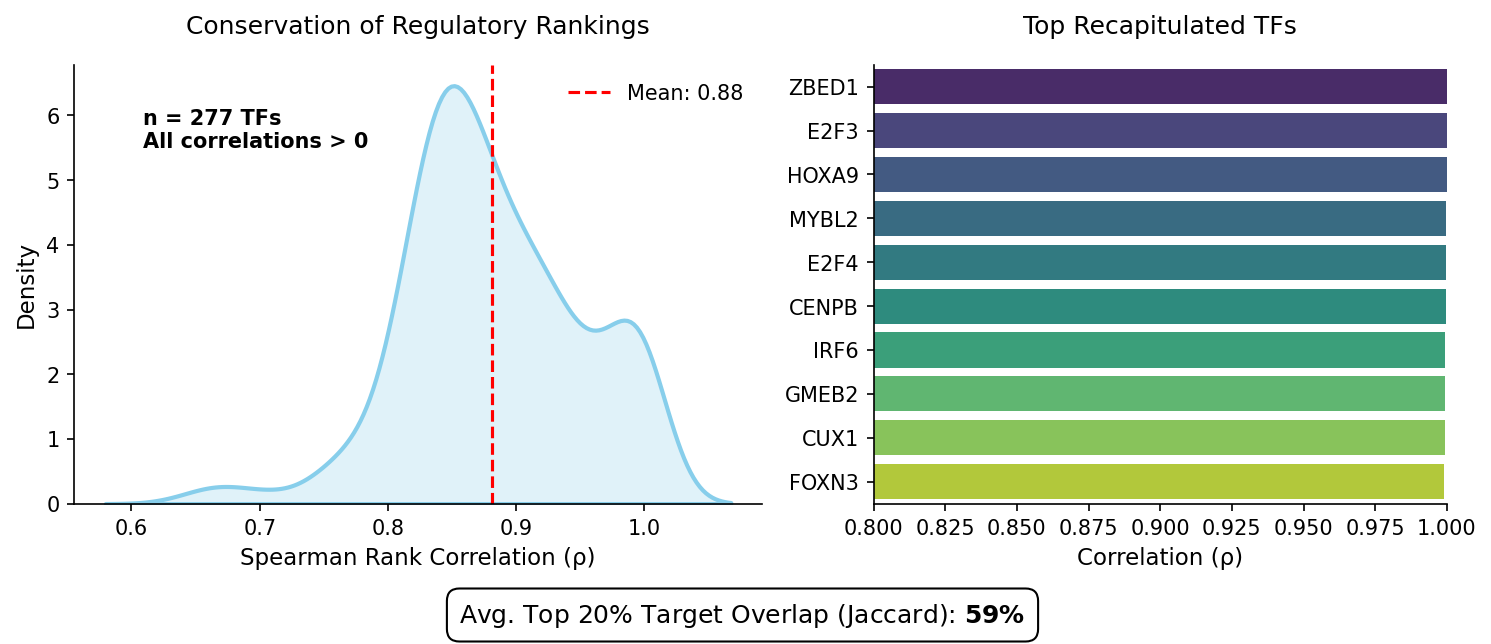

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# --- Load your data (Assuming tf_df was saved in your previous step) ---
# tf_df = pd.read_csv("uv_leading_fixed/per_tf_grn_comparison.csv")

# Styling
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

fig = plt.figure(figsize=(10, 4), dpi=150)
gs = fig.add_gridspec(1, 2, width_ratios=[1.2, 1])

# ---------------------------------------------------------
# PANEL A: Distribution of TF Correlations
# ---------------------------------------------------------
ax0 = fig.add_subplot(gs[0])
sns.kdeplot(tf_df['per_tf_spearman'], fill=True, color='skyblue', ax=ax0, lw=2)
ax0.axvline(tf_df['per_tf_spearman'].mean(), color='red', linestyle='--', label=f'Mean: {tf_df["per_tf_spearman"].mean():.2f}')

# Add summary stats as text
ax0.text(0.1, 0.9, f"n = {len(tf_df)} TFs\nAll correlations > 0", 
         transform=ax0.transAxes, fontsize=10, fontweight='bold', verticalalignment='top')

ax0.set_xlabel("Spearman Rank Correlation (ρ)", fontsize=11)
ax0.set_ylabel("Density", fontsize=11)
ax0.set_title("Conservation of Regulatory Rankings", fontsize=12, pad=15)
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)
ax0.legend(frameon=False)

# ---------------------------------------------------------
# PANEL B: Top 10 Best-Matching TFs
# ---------------------------------------------------------
ax1 = fig.add_subplot(gs[1])
top_10 = tf_df.head(10)
sns.barplot(data=top_10, x='per_tf_spearman', y='tf', palette='viridis', ax=ax1)

ax1.set_xlim(0.8, 1.0) # Zoom in to see differences in high performers
ax1.set_xlabel("Correlation (ρ)", fontsize=11)
ax1.set_ylabel("")
ax1.set_title("Top Recapitulated TFs", fontsize=12, pad=15)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ---------------------------------------------------------
# Final Touch: Add the Jaccard Metric as a text box or annotation
# ---------------------------------------------------------
fig.text(0.5, -0.05, 
         r"Avg. Top 20% Target Overlap (Jaccard): $\bf{59\%}$", 
         ha="center", fontsize=12, bbox=dict(facecolor='none', edgecolor='black', boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# --- 1. Identify the "Active" Subspace ---
# Instead of all genes, let's look at genes that are 'targets' in at least one model
# (sum of absolute weights > 0)
active_mask = (np.abs(A_pred_shared).sum(axis=1) > 0) | (np.abs(A_co_shared).sum(axis=1) > 0)
A_pred_active = A_pred_shared[active_mask, :]
A_co_active = A_co_shared[active_mask, :]

honest_metrics = []

for ti, tf_name in enumerate(common_tfs):
    w_pred = A_pred_shared[:, ti]
    w_co = A_co_shared[:, ti]
    
    # A. The "All Genes" Rho (what you have now - likely inflated)
    rho_all, _ = spearmanr(w_pred, w_co)
    
    # B. The "Top Targets" Rho (More Honest)
    # We take the top 500 genes according to the AVERAGE rank of both models
    combined_strength = np.abs(w_pred) + np.abs(w_co)
    top_indices = np.argsort(combined_strength)[-500:] # Focus on the top 500 'potential' targets
    
    rho_top, _ = spearmanr(w_pred[top_indices], w_co[top_indices])
    
    # C. Jaccard Overlap (Top 10%)
    k = max(1, int(0.10 * len(common_genes)))
    set_pred = set(np.argsort(np.abs(w_pred))[-k:])
    set_co = set(np.argsort(np.abs(w_co))[-k:])
    jaccard = len(set_pred & set_co) / len(set_pred | set_co)
    
    honest_metrics.append({
        "tf": tf_name,
        "rho_all": rho_all,
        "rho_top_500": rho_top,
        "jaccard_top_10pct": jaccard
    })

df_honest = pd.DataFrame(honest_metrics)

# Print comparison
print(f"Mean Rho (All Genes): {df_honest['rho_all'].mean():.3f}")
print(f"Mean Rho (Top 500):   {df_honest['rho_top_500'].mean():.3f}")

Mean Rho (All Genes): 0.051
Mean Rho (Top 500):   0.111


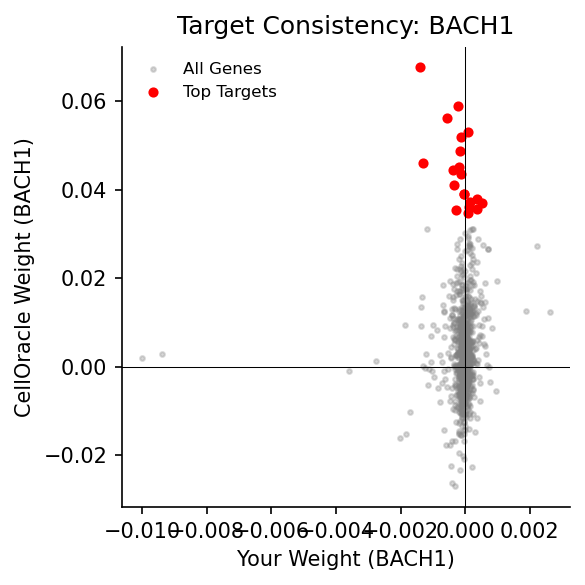

In [20]:
def plot_tf_comparison(tf_name, df_pred, df_co, genes):
    idx = list(common_tfs).index(tf_name)
    x = A_pred_shared[:, idx]
    y = A_co_shared[:, idx]
    
    plt.figure(figsize=(4, 4), dpi=150)
    
    # Scatter of all genes (use alpha for density)
    plt.scatter(x, y, s=5, alpha=0.3, color='grey', label='All Genes')
    
    # Highlight top 20 genes to show 'hits'
    top_idx = np.argsort(np.abs(x) + np.abs(y))[-20:]
    plt.scatter(x[top_idx], y[top_idx], s=15, color='red', label='Top Targets')
    
    plt.axhline(0, color='black', lw=0.5)
    plt.axvline(0, color='black', lw=0.5)
    
    plt.xlabel(f"Your Weight ({tf_name})")
    plt.ylabel(f"CellOracle Weight ({tf_name})")
    plt.title(f"Target Consistency: {tf_name}")
    plt.legend(frameon=False, fontsize=8)
    
    # Remove spines
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

# Example: Plot the 5th TF in your list
plot_tf_comparison(common_tfs[5], A_pred_shared, A_co_shared, common_genes)

## Step 10: Stability of U/V via repeated NMF on final A

In [15]:
# ─── NMF stability: use init="random" for perturbed runs ───────────────────
A_learned = np.load("uv_leading_fixed/A_learned.npy")   # <-- UPDATED NAME

A_final = A_learned
A_pos   = np.abs(A_final)

NMF_RANK = min(20, min(A_pos.shape) - 1)
N_RUNS   = 20
TOP_GENES, TOP_TFS = 25, 15 #

# Reference decomposition (deterministic init)
nmf_ref = NMF(n_components=NMF_RANK, init="nndsvda", random_state=0, max_iter=2000)
W_ref   = nmf_ref.fit_transform(A_pos)
H_ref   = nmf_ref.components_
ref_modules = module_sets_from_nmf(W_ref, H_ref, top_genes=TOP_GENES, top_tfs=TOP_TFS)

run_scores, run_gene_scores, run_tf_scores = [], [], []
diffs = []

for seed in range(1, N_RUNS + 1):
    # FIXED: use init="random" so each run is genuinely different
    nmf = NMF(n_components=NMF_RANK, init="random", random_state=seed, max_iter=2000)
    W   = nmf.fit_transform(A_pos)
    H   = nmf.components_
    diffs.append(np.linalg.norm(W - W_ref))
    cur_modules = module_sets_from_nmf(W, H, top_genes=TOP_GENES, top_tfs=TOP_TFS)

    match = match_module_sets(ref_modules, cur_modules)
    run_scores.append(match["mean_conservation"])
    Sg, St = [], []
    for (rg, rt), (cg, ct) in zip(ref_modules, cur_modules):
        Sg.append(jaccard(rg, cg))
        St.append(jaccard(rt, ct))
    run_gene_scores.append(float(np.mean(Sg)))
    run_tf_scores.append(float(np.mean(St)))

stability_results = {
    "nmf_rank": NMF_RANK,
    "n_runs": N_RUNS,
    "mean_module_conservation": float(np.mean(run_scores)),
    "std_module_conservation": float(np.std(run_scores)),
    "mean_gene_conservation": float(np.mean(run_gene_scores)),
    "mean_tf_conservation": float(np.mean(run_tf_scores)),
}
print("NMF stability (random init):", stability_results)
print("mean W difference:", np.mean(diffs))
# A well-trained model should give 0.6-0.85 here. If still 1.0, A is rank-deficient.

NMF stability (random init): {'nmf_rank': 20, 'n_runs': 20, 'mean_module_conservation': 1.0, 'std_module_conservation': 0.0, 'mean_gene_conservation': 1.0, 'mean_tf_conservation': 1.0}


In [8]:
from scipy.optimize import linear_sum_assignment

def match_module_sets(ref_modules, cur_modules):
    n = len(ref_modules)
    sim = np.zeros((n, n))

    # similarity matrix (gene + TF overlap)
    for i, (rg, rt) in enumerate(ref_modules):
        for j, (cg, ct) in enumerate(cur_modules):
            sim[i, j] = 0.5 * jaccard(rg, cg) + 0.5 * jaccard(rt, ct)

    # Hungarian matching (maximize similarity)
    row_ind, col_ind = linear_sum_assignment(-sim)

    scores = sim[row_ind, col_ind]

    return {
        "mean_conservation": float(np.mean(scores)),
        "pairs": list(zip(row_ind, col_ind))  # ✅ ADD THIS
    }

In [9]:
# ─── NMF stability: use init="random" for perturbed runs ───────────────────
A_learned = np.load("uv_leading_fixed/A_learned.npy")   # <-- UPDATED NAME

A_final = A_learned
A_pos   = np.abs(A_final)

NMF_RANK = min(20, min(A_pos.shape) - 1)
N_RUNS   = 20
TOP_GENES, TOP_TFS = 70, 40 #

# Reference decomposition (deterministic init)
nmf_ref = NMF(n_components=NMF_RANK, init="nndsvda", random_state=0, max_iter=2000)
W_ref   = nmf_ref.fit_transform(A_pos)
H_ref   = nmf_ref.components_
ref_modules = module_sets_from_nmf(W_ref, H_ref, top_genes=TOP_GENES, top_tfs=TOP_TFS)

run_scores, run_gene_scores, run_tf_scores = [], [], []
diffs = []

for seed in range(1, N_RUNS + 1):
    # FIXED: use init="random" so each run is genuinely different
    nmf = NMF(n_components=NMF_RANK, init="random", random_state=seed, max_iter=2000)
    W   = nmf.fit_transform(A_pos)
    H   = nmf.components_
    diffs.append(np.linalg.norm(W - W_ref))
    cur_modules = module_sets_from_nmf(W, H, top_genes=TOP_GENES, top_tfs=TOP_TFS)

    match = match_module_sets(ref_modules, cur_modules)
    run_scores.append(match["mean_conservation"])
    Sg, St = [], []
    for i_ref, i_cur in match["pairs"]:
        rg, rt = ref_modules[i_ref]
        cg, ct = cur_modules[i_cur]
    
        Sg.append(jaccard(rg, cg))
        St.append(jaccard(rt, ct))
        Sg.append(jaccard(rg, cg))
        St.append(jaccard(rt, ct))
    run_gene_scores.append(float(np.mean(Sg)))
    run_tf_scores.append(float(np.mean(St)))

stability_results = {
    "nmf_rank": NMF_RANK,
    "n_runs": N_RUNS,
    "mean_module_conservation": float(np.mean(run_scores)),
    "std_module_conservation": float(np.std(run_scores)),
    "mean_gene_conservation": float(np.mean(run_gene_scores)),
    "mean_tf_conservation": float(np.mean(run_tf_scores)),
}
print("NMF stability (random init):", stability_results)
print("mean W difference:", np.mean(diffs))
# A well-trained model should give 0.6-0.85 here. If still 1.0, A is rank-deficient.

NMF stability (random init): {'nmf_rank': 20, 'n_runs': 20, 'mean_module_conservation': 1.0, 'std_module_conservation': 0.0, 'mean_gene_conservation': 1.0, 'mean_tf_conservation': 1.0}
mean W difference: 3.8773544


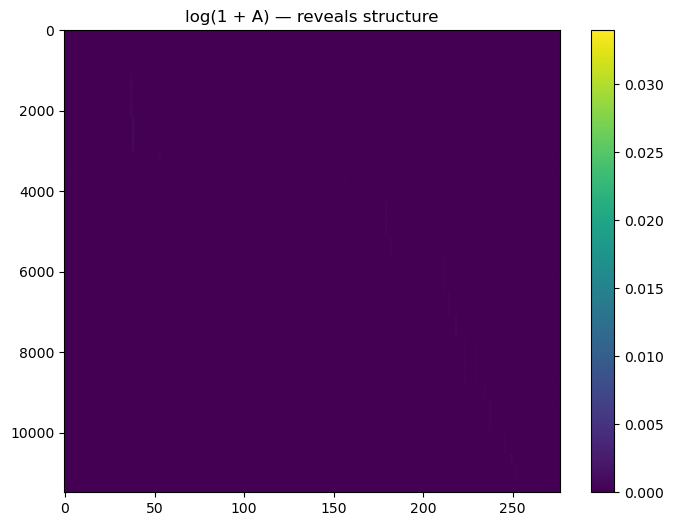

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# get module assignment from reference NMF
gene_module = np.argmax(W_ref, axis=1)   # gene → module
tf_module   = np.argmax(H_ref, axis=0)   # tf → module

# sort indices by module
gene_order = np.argsort(gene_module)
tf_order   = np.argsort(tf_module)

A_sorted = A_pos[gene_order][:, tf_order]

A_vis = np.log1p(A_sorted)  # compress dynamic range

plt.figure(figsize=(8, 6))
plt.imshow(A_vis, aspect='auto', cmap='viridis')
plt.title("log(1 + A) — reveals structure")
plt.colorbar()
plt.show()

In [17]:
print("A max:", A_final.max())
print("A mean:", A_final.mean())
print("A std:", A_final.std())

A max: 0.01611584
A mean: -7.669615e-07
A std: 0.00010379049


## Step 11: Pseudotime arrow agreement

In [29]:
pseudo = np.asarray(rna_adata.obs["facs_pseudotime"].values, dtype=float)
pseudo = pseudo[cell_idx]  # keep in sync with X / V_pred

# gene-space agreement
gene_arrow_metrics = pseudotime_arrow_agreement(
    X_space=X,
    V_pred=A_learned.detach().cpu().numpy() @ np.zeros((A_learned.shape[1], 1)).T if False else V_pred,
    pseudotime=pseudo,
    k=30
)

print("\nPseudotime arrow agreement in gene space")
print({k: v for k, v in gene_arrow_metrics.items() if k != "cosines"})

# UMAP-space agreement using your predicted velocities
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

eps = 0.5
X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)
V_umap_raw = (X_pert_umap - X_umap) / eps

umap_arrow_metrics = pseudotime_arrow_agreement(
    X_space=X_umap,
    V_pred=V_umap_raw,
    pseudotime=pseudo,
    k=30
)

print("\nPseudotime arrow agreement in UMAP space")
print({k: v for k, v in umap_arrow_metrics.items() if k != "cosines"})

with open("uv_leading_fixed/pseudotime_arrow_metrics.json", "w") as f:
    json.dump(
        {
            "gene_space": {k: (float(v) if isinstance(v, (np.floating, float, int)) else v)
                           for k, v in gene_arrow_metrics.items() if k != "cosines"},
            "umap_space": {k: (float(v) if isinstance(v, (np.floating, float, int)) else v)
                           for k, v in umap_arrow_metrics.items() if k != "cosines"},
        },
        f,
        indent=2
    )


Pseudotime arrow agreement in gene space
{'mean_cosine': 0.014638096780968272, 'fraction_positive': 0.7323383084577114, 'n_valid': 1005}


/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



Pseudotime arrow agreement in UMAP space
{'mean_cosine': -0.0897910721196013, 'fraction_positive': 0.44190665342601787, 'n_valid': 1007}


## Step 12: Visualize velocity in PCA space

In [25]:
# 1. Get the gene-space matrix (1035 cells, 11483 genes)
# This was defined earlier in your 'Alignment Block'
X_genes = X_full[:, gene_idx] 
print(f"X_genes shape: {X_genes.shape}") # MUST BE (1035, 11483)

# 2. Fit PCA on the GENES
pca = PCA(n_components=10)
X_pca = pca.fit_transform(X_genes) 
print(f"Components shape: {pca.components_.shape}") # MUST BE (10, 11483)

# 3. Project Velocity
# V_pred is (1035, 11483), pca.components_.T is (11483, 10)
V_pca = V_pred @ pca.components_.T
print(f"V_pca shape: {V_pca.shape}") # Should now be (1035, 10)

X_genes shape: (1035, 11483)
Components shape: (10, 11483)
V_pca shape: (1035, 10)


Performing Tangent Projection for PCA space...


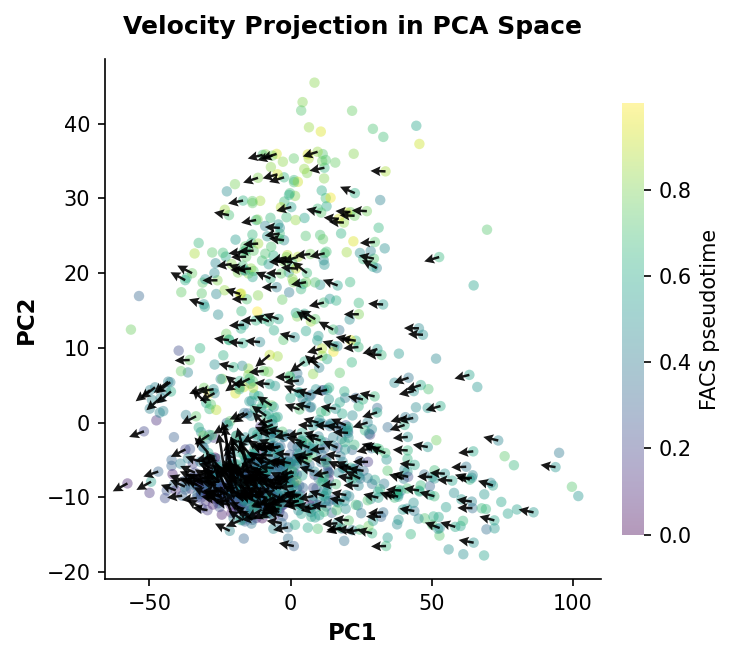

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# 1. Standardize and PCA (Keep this, it's good for the background)
X_plot = np.log1p(X_genes)
X_plot = StandardScaler().fit_transform(X_plot)
pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X_plot)

# ============================================================
# FIXED STEP: Tangent Manifold Projection for PCA
# ============================================================
print("Performing Tangent Projection for PCA space...")
k_exp = 30
nn_pca = NearestNeighbors(n_neighbors=k_exp).fit(X_pca) 
_, idx_pca = nn_pca.kneighbors(X_pca)

N = X_pca.shape[0]
V_pca_projected = np.zeros((N, 2), dtype=np.float32)

# Make sure we use the 11483-gene matrix here
# If you named it X_genes or X_full_aligned, use that variable
X_for_svd = X_genes 

for i in range(N):
    # 1. Local geometry in PCA space (2D)
    local_vis = X_pca[idx_pca[i], :2] - X_pca[i, :2] # (K, 2)
    
    # 2. Local geometry in GENE space (G columns)
    # This must match V_pred's 11483 columns
    local_gene = X_for_svd[idx_pca[i]] - X_for_svd[i] # (K, 11483)
    
    # 3. SVD to find the mapping
    U, S, Vt = np.linalg.svd(local_gene, full_matrices=False)
    
    # Vt.T will now be (11483, K), matching V_pred[i] (11483,)
    gene_coeffs = V_pred[i] @ Vt.T 
    
    # 4. Map back to visualization space
    V_pca_projected[i] = np.mean(local_vis * (U @ gene_coeffs)[:, np.newaxis], axis=0)

# Apply Smoothing
V_smooth = 0.7 * V_pca_projected + 0.3 * np.array([
    V_pca_projected[idx_pca[i]].mean(axis=0) for i in range(N)
])

# Now run your plotting code using V_smooth instead of V_pcaV_pca = V_pred @ pca.components_.T

# --- 2. SETUP FIGURE ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=150)

# --- 3. PLOT BACKGROUND ---
sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1], 
    c=pseudo,
    cmap="viridis", 
    s=25, 
    alpha=0.4, 
    edgecolors='none', 
    rasterized=True
)

# --- 4. DECIPHER-STYLE SMOOTHING ---
X = X_pca
V = V_smooth # Use raw projected velocity for the smoothing step
n_arrows = min(400, len(X))
sample_idx = np.random.choice(len(X), n_arrows, replace=False)

# kNN smoothing in CELL space
k = 15
nbrs = NearestNeighbors(n_neighbors=k).fit(X)
_, idx = nbrs.kneighbors(X[sample_idx])
V_avg = V[idx].mean(axis=1)

# Preserve magnitude and normalize for visualization
norm = np.linalg.norm(V_avg, axis=1, keepdims=True)
V_dir = V_avg / (norm + 1e-9)

# Adjust arrow_scale based on the spread of the PCA coordinates
# This ensures arrows are visible but not overwhelming
arrow_scale = 0.5 * (np.max(X_pca[:, 0]) - np.min(X_pca[:, 0])) / 15
V_final = V_dir * arrow_scale

# --- 5. QUIVER ---
ax.quiver(
    X[sample_idx, 0], X[sample_idx, 1],
    V_final[:, 0], V_final[:, 1],
    color='black',
    alpha=0.9,
    angles='xy',
    scale_units='xy',
    scale=1.0, # Now 1.0 because we pre-scaled V_final
    width=0.005,
    headwidth=4,
    headlength=4,
    headaxislength=3.5
)

# --- 6. CLEAN LABELS ---
ax.set_xlabel("PC1", fontsize=11, fontweight='bold')
ax.set_ylabel("PC2", fontsize=11, fontweight='bold')
ax.set_title("Velocity Projection in PCA Space", fontsize=12, pad=12, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("FACS pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

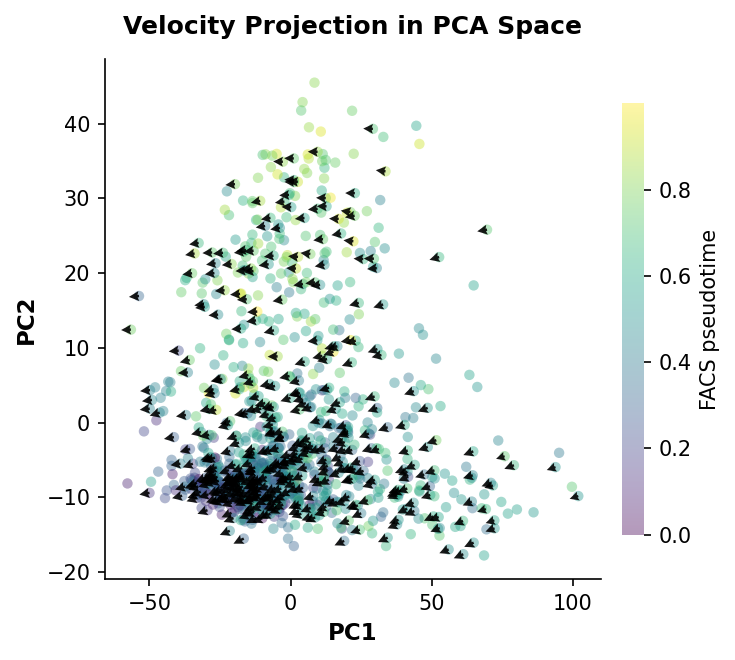

In [29]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# --- 1. DATA PREP (The secret to a "nice" PCA plot) ---
# Standardize and Log-transform so PCA isn't crushed by outliers
X_plot = np.log1p(X_genes)
X_plot = StandardScaler().fit_transform(X_plot)

# Re-run PCA on the nice, scaled data
pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X_plot)

# Re-project velocity using the components from the scaled data
V_pca = V_pred @ pca.components_.T

# --- 2. SETUP FIGURE ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=150)

# --- 3. PLOT BACKGROUND ---
sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1], 
    c=pseudo,
    cmap="viridis", 
    s=25, 
    alpha=0.4, 
    edgecolors='none', 
    rasterized=True
)

# --- 4. DECIPHER-STYLE SMOOTHING ---
X = X_pca
V = V_pca  # Use raw projected velocity for the smoothing step
n_arrows = min(400, len(X))
sample_idx = np.random.choice(len(X), n_arrows, replace=False)

# kNN smoothing in CELL space
k = 15
nbrs = NearestNeighbors(n_neighbors=k).fit(X)
_, idx = nbrs.kneighbors(X[sample_idx])
V_avg = V[idx].mean(axis=1)

# Preserve magnitude and normalize for visualization
norm = np.linalg.norm(V_avg, axis=1, keepdims=True)
V_dir = V_avg / (norm + 1e-9)

# Adjust arrow_scale based on the spread of the PCA coordinates
# This ensures arrows are visible but not overwhelming
arrow_scale = 0.5 * (np.max(X_pca[:, 0]) - np.min(X_pca[:, 0])) / 15
V_final = V_dir * arrow_scale

# --- 5. QUIVER ---
ax.quiver(
    X[sample_idx, 0], X[sample_idx, 1],
    V_final[:, 0], V_final[:, 1],
    color='black',
    alpha=0.9,
    angles='xy',
    scale_units='xy',
    scale=1.0, # Now 1.0 because we pre-scaled V_final
    width=0.005,
    headwidth=4,
    headlength=4,
    headaxislength=3.5
)

# --- 6. CLEAN LABELS ---
ax.set_xlabel("PC1", fontsize=11, fontweight='bold')
ax.set_ylabel("PC2", fontsize=11, fontweight='bold')
ax.set_title("Velocity Projection in PCA Space", fontsize=12, pad=12, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("FACS pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

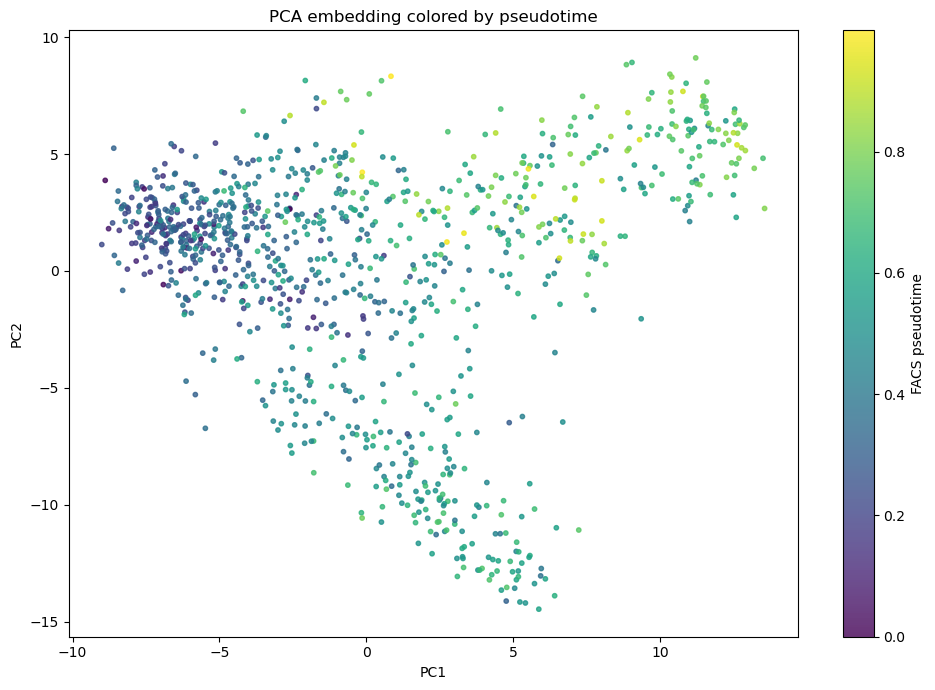

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# PCA embedding
X_pca = adata.obsm["X_pca"][:, :2]

# pseudotime (or swap for any obs label)
pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=10,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA embedding colored by pseudotime")

plt.tight_layout()
plt.show()

NameError: name 'V_pca_smooth' is not defined

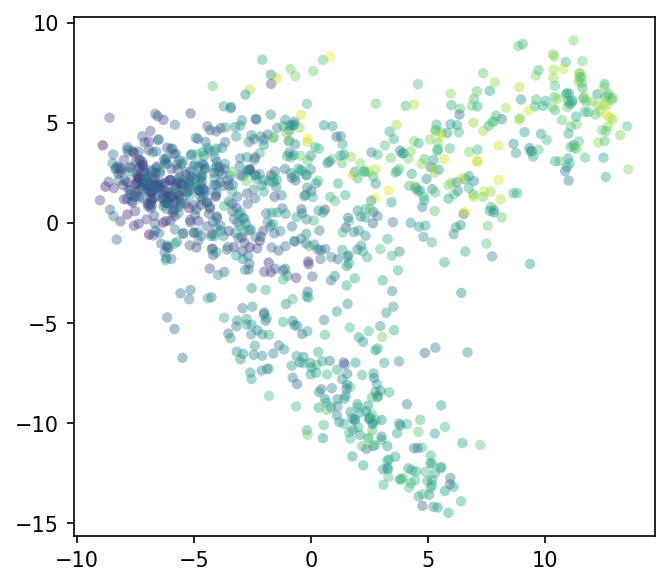

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binned_statistic_2d

# --- Fix for Font Errors ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'

# 1. Setup Figure (Adjusted for clean slide proportions)
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=150)

# 2. Plot Cells (The Background)
sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1], 
    c=pseudo,
    cmap="viridis", 
    s=25,               # Visible on slides
    alpha=0.4,          # High contrast backdrop for black arrows
    edgecolors='none', 
    rasterized=True
)

from sklearn.neighbors import NearestNeighbors

# =========================================================
# 3. DECIPHER-STYLE SMOOTHING (IMPORTANT FIX)
# =========================================================

X = X_pca
V = V_pca_smooth  # or V_pca if you prefer raw signal

n_arrows = min(400, len(X))
sample_idx = np.random.choice(len(X), n_arrows, replace=False)

# kNN smoothing in CELL space (NOT bins)
k = 15
nbrs = NearestNeighbors(n_neighbors=k).fit(X)
_, idx = nbrs.kneighbors(X[sample_idx])

V_avg = V[idx].mean(axis=1)

# preserve magnitude (key difference from your broken version)
norm = np.linalg.norm(V_avg, axis=1, keepdims=True)
V_dir = V_avg / (norm + 1e-9)

arrow_scale = 0.5 * np.percentile(norm, 90)
V_final = V_dir * arrow_scale

# =========================================================
# 4. QUIVER (decipher style settings)
# =========================================================
ax.quiver(
    X[sample_idx, 0], X[sample_idx, 1],
    V_final[:, 0], V_final[:, 1],

    color='black',
    alpha=0.9,

    angles='xy',
    scale_units='xy',
    scale=1.2,              # CRITICAL (no auto shrinking)

    width=0.005,

    headwidth=4,
    headlength=4,
    headaxislength=3.5
)

# 5. Clean Labels and Aesthetics
ax.set_xlabel("PC1", fontsize=11, fontweight='bold')
ax.set_ylabel("PC2", fontsize=11, fontweight='bold')
ax.set_title("'Velocity' Projection in PCA Space", fontsize=12, pad=12, fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("FACS pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

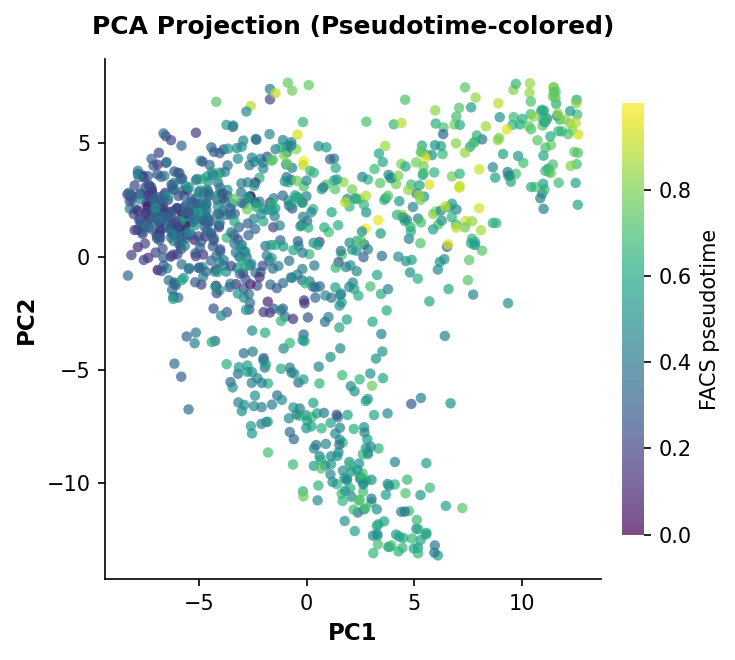

In [42]:
import matplotlib.pyplot as plt
import numpy as np

# --- Fix for Font Errors ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'

# 1. Setup Figure (Adjusted for clean slide proportions)
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=150)

# 2. Plot Cells
sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1], 
    c=pseudo,
    cmap="viridis", 
    s=25,               # Visible on slides
    alpha=0.7,          # Increased alpha now that arrows are gone
    edgecolors='none', 
    rasterized=True
)

# 3. Clean Labels and Aesthetics
ax.set_xlabel("PC1", fontsize=11, fontweight='bold')
ax.set_ylabel("PC2", fontsize=11, fontweight='bold')
ax.set_title("PCA Projection (Pseudotime-colored)", fontsize=12, pad=12, fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label("FACS pseudotime", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()